In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from xgboost import XGBRegressor

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score, mean_absolute_error

- APLICAR VALIDAÇÃO CRUZADA PARA DEFINIR HIPERPARÂMETROS
- ESTUDAR OS HIPERPARÂMETROS NA BIBLIOTECA

In [39]:
df = pd.read_csv('databasev4_2.csv')
# df = df[(df['pos_x']>0.08) & (df['pos_x']<0.2)].reset_index(drop=True)

X = df.drop(columns=['soil_type','radius','pos_x','pos_y','presence'])
Y = df['pos_y']

# na = ["a_rel_10mm","a_rel_20mm","a_rel_30mm","a_rel_40mm","eco2_atraso","eco2_razao"]
# X = X.drop(columns=na)

x_train, x_test, y_train, y_test, = train_test_split(X,Y,test_size=0.2,random_state=42)

Random Forest Regressor

In [40]:
mse = []
for i in np.arange(1,100,2):
    model_rf = RandomForestRegressor(n_estimators=i,random_state=42,n_jobs=4,)

    model_rf.fit(x_train,y_train)

    y_pred_rf = model_rf.predict(x_test)
    mse.append(mean_squared_error(y_test, y_pred_rf))

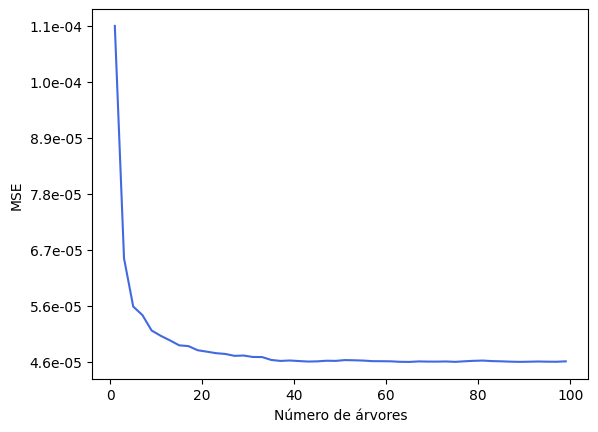

In [45]:
mse = np.array(mse)

ytik = np.linspace(mse.min(),mse.max(),7)

fig, ax = plt.subplots(1,1)

plt.xlabel('Número de árvores')
plt.ylabel('MSE')
plt.plot(np.arange(1,100,2),mse,color='royalblue')
xlabels = [f'{y:1.1e}' for y in ytik]
ax.set_yticks(ytik, labels=xlabels)
plt.show()

In [42]:

model_rf = RandomForestRegressor(n_estimators=100,random_state=42,n_jobs=4,)

model_rf.fit(x_train,y_train)

y_pred_rf = model_rf.predict(x_test)

print('R²:', r2_score(y_test, y_pred_rf))
print('RMSE:', np.sqrt(mean_squared_error(y_test, y_pred_rf)))
print('MAE:', mean_absolute_error(y_test, y_pred_rf))

R²: 0.7988140768592737
RMSE: 0.0067585045941414
MAE: 0.005335657894736841


Gradient Boosting

In [59]:
model_hgb = HistGradientBoostingRegressor(learning_rate=0.01, max_iter=10000, max_leaf_nodes=31,
                                          early_stopping=True, validation_fraction=0.15, n_iter_no_change=50,random_state=42)

model_hgb.fit(x_train,y_train)

y_pred_hgb = model_hgb.predict(x_test)

print('R²:', r2_score(y_test, y_pred_hgb))
print('RMSE:', np.sqrt(mean_squared_error(y_test, y_pred_hgb)))
print('MAE:', mean_absolute_error(y_test, y_pred_hgb))

R²: 0.8118053059487383
RMSE: 0.0065366541249860495
MAE: 0.005151627021520797


XGBoost

In [ ]:
for

In [44]:
model_xg = XGBRegressor(n_estimators=300, learning_rate=0.05, max_depth=6,
                    subsample=0.8, colsample_bytree=0.8, objective='reg:squarederror', random_state=42,n_jobs=-1)

model_xg.fit(x_train,y_train)

y_pred_xg = model_xg.predict(x_test)

print('R²:', r2_score(y_test, y_pred_xg))
print('RMSE:', np.sqrt(mean_squared_error(y_test, y_pred_xg)))
print('MAE:', mean_absolute_error(y_test, y_pred_xg))

R²: 0.8069612389405283
RMSE: 0.0066202452605721
MAE: 0.005172771096355035
